# Final Graphs Generation

This notebook generates the Min/Max/Mean error bar graphs for PSNR and SSIM across JPEG, JPEG2000, AVIF, and SMoE algorithms.

It computes the metrics dynamically for JPEG, JPEG2000, and AVIF by running the compression on the fly. For SMoE, it reads the pre-computed reconstruction images from the `SMoE` results folders.


In [7]:
# Install necessary packages
%pip install pillow-heif
%pip install matplotlib
%pip install numpy
%pip install pillow

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.




AVIF support enabled via pillow_heif
Using images from: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images

Processing Gradient_sq_gray...


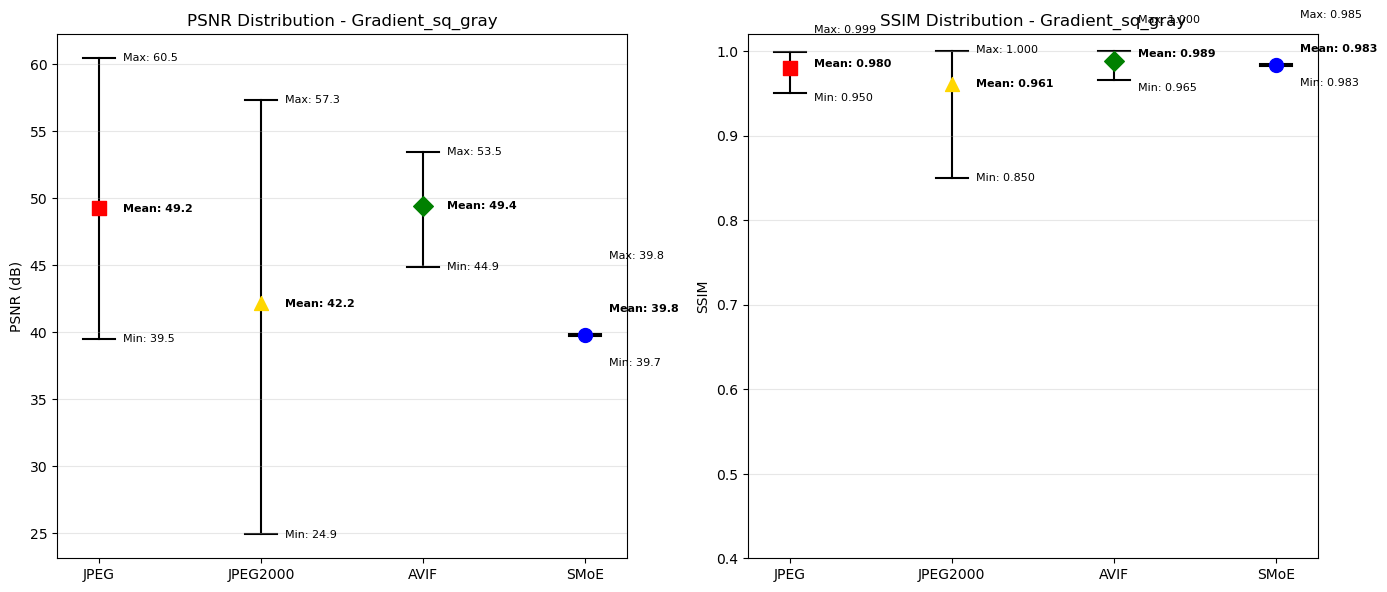


Processing Grass_sq_gray...


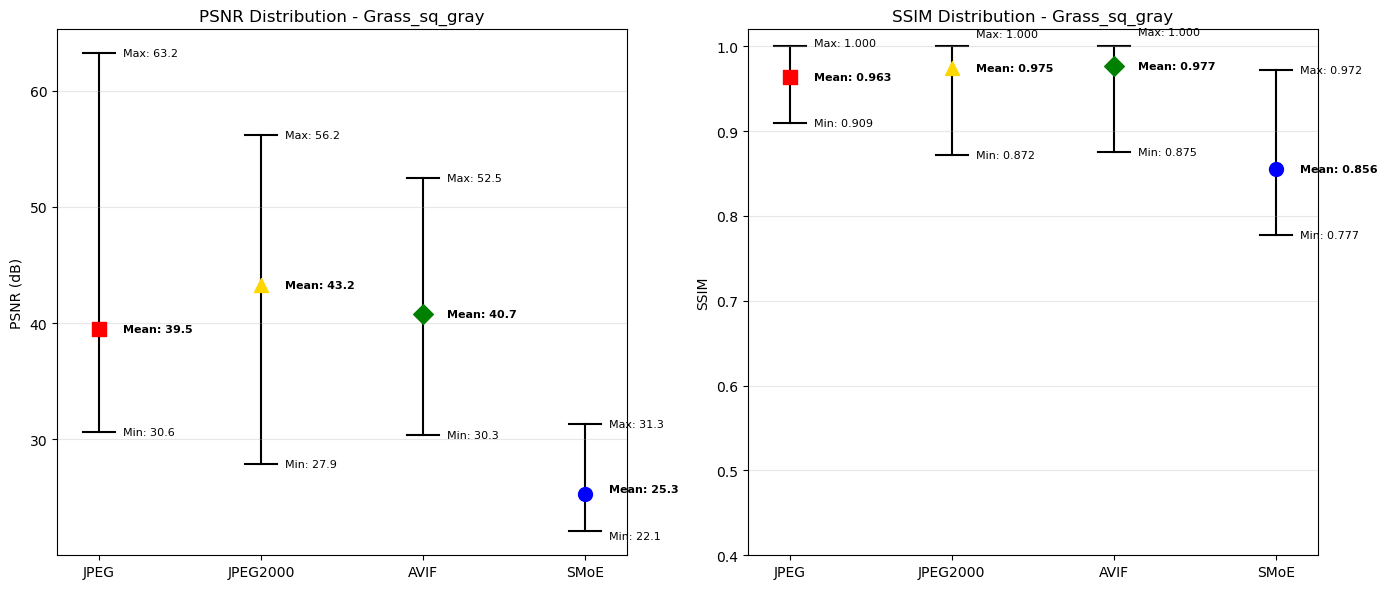


Processing Mixed_sq_gray...


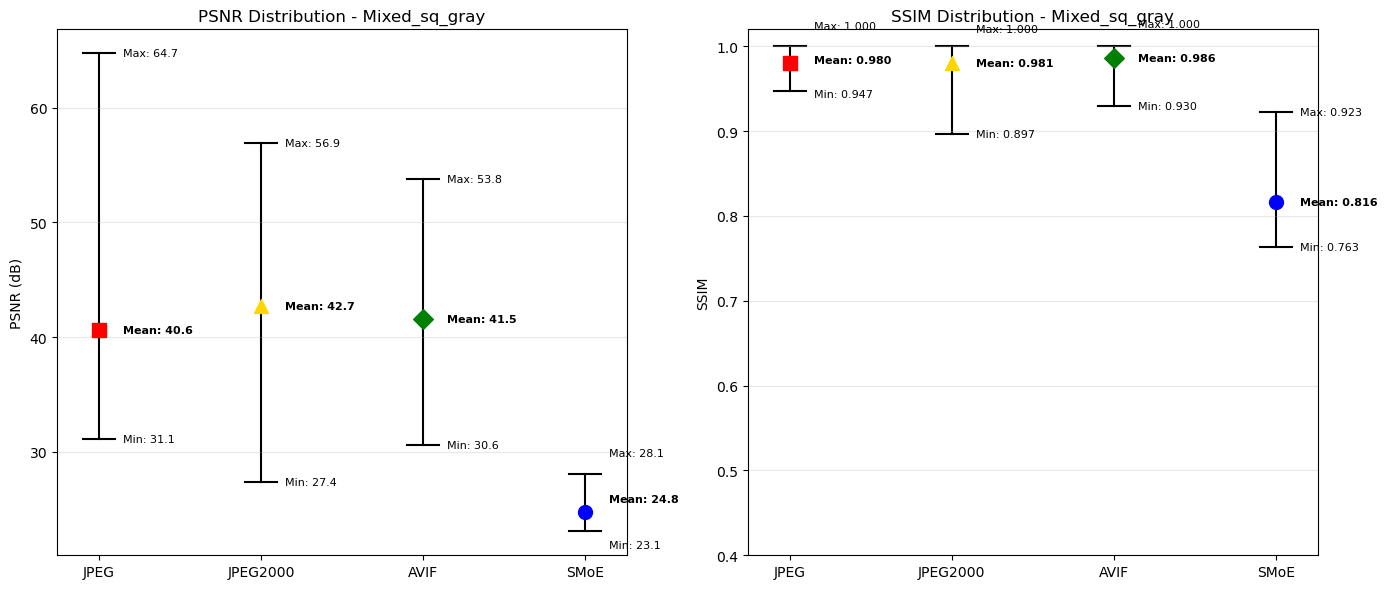


Processing Nature_sq_gray...


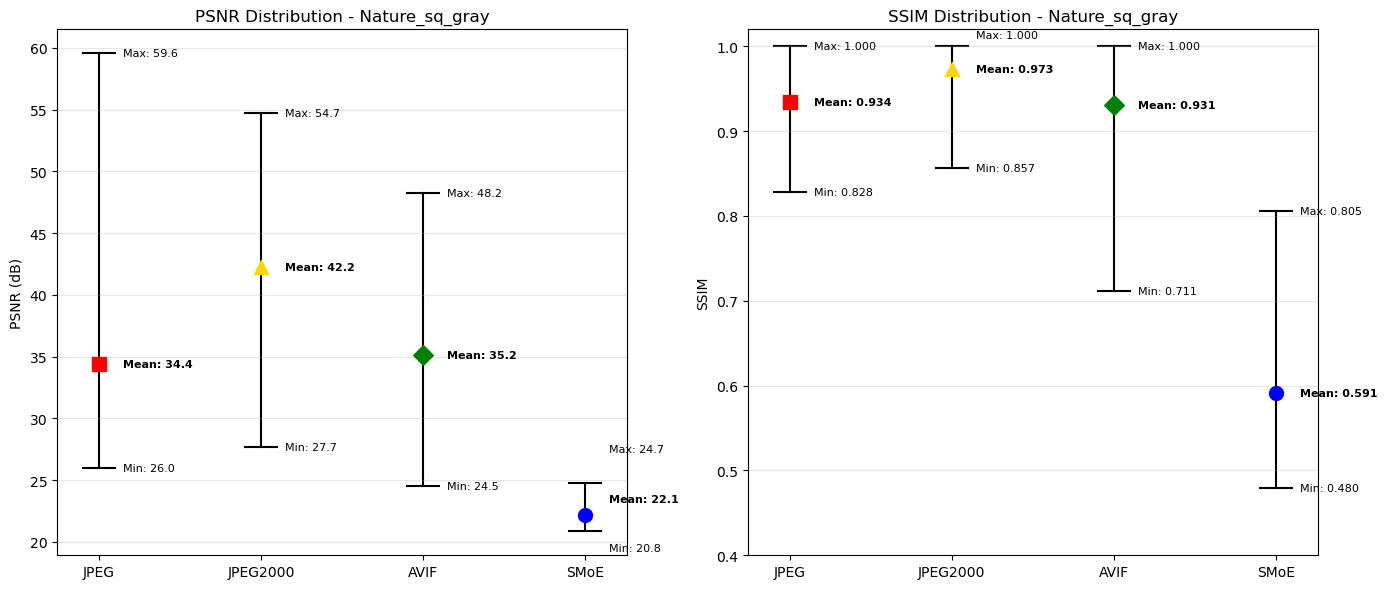


Processing SharpEdges_sq_gray...


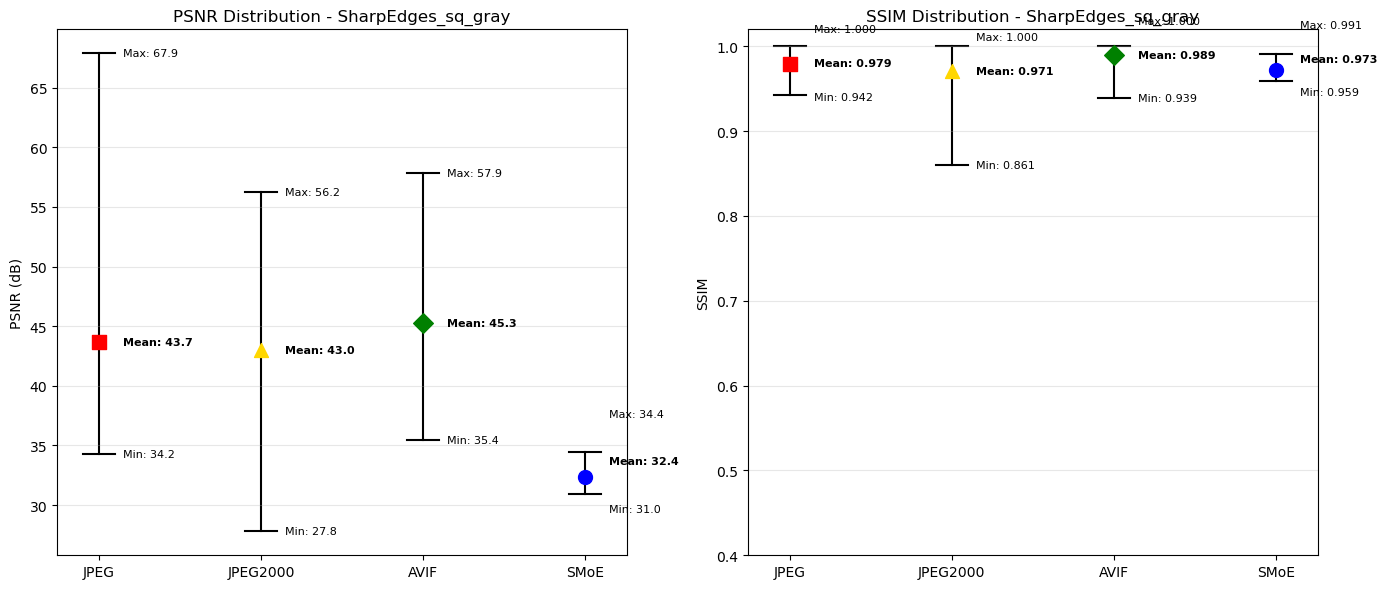


Generating Aggregate Graphs (Mean of Min/Mean/Max across all images)


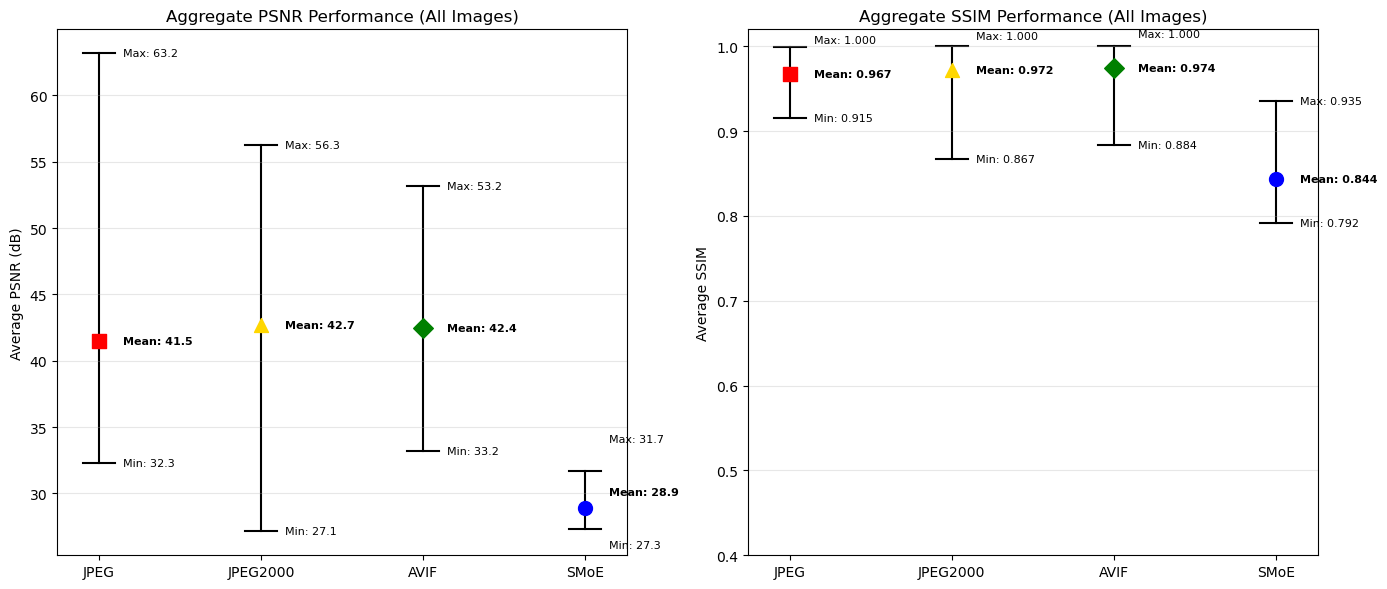

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import io
import os

# Try to import pillow_heif for AVIF support
try:
    from pillow_heif import register_heif_opener
    register_heif_opener()
    print("AVIF support enabled via pillow_heif")
except ImportError:
    print("pillow_heif not found. AVIF metrics might fail if not installed.")

# --- Configuration ---
# Workspace root
workspace_root = Path(r'c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final')

# Image paths - Try to locate the images
# First check the standard Images folder
images_path = Path(r'c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images')
if not images_path.exists():
    # Fallback to SMoE data folder which we know exists
    print(f"Images folder not found at {images_path}, checking SMoE data folder...")
    images_path = workspace_root / 'SMoE' / '16k_100i_3535s' / 'tf-smoe-master' / 'data'

if not images_path.exists():
    print(f"CRITICAL: Could not find images in {images_path}")
else:
    print(f"Using images from: {images_path}")

image_names = ['Gradient_sq_gray', 'Grass_sq_gray', 'Mixed_sq_gray', 'Nature_sq_gray', 'SharpEdges_sq_gray']

# --- Metrics Functions ---
def psnr(img1, img2, data_range=255.0):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    mse = np.mean((x - y) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(data_range) - 10 * np.log10(mse)

def _box_filter_same(img, w):
    if img.ndim == 2:
        img = img[..., None]
        squeeze = True
    else:
        squeeze = False
    pad = w // 2
    img_p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    tmp = np.cumsum(img_p, axis=0)
    tmp = tmp[w:, :, :] - tmp[:-w, :, :]
    tmp2 = np.cumsum(tmp, axis=1)
    res = tmp2[:, w:, :] - tmp2[:, :-w, :]
    res = res / (w * w)
    if squeeze:
        return res[..., 0]
    return res

def ssim(img1, img2, data_range=255.0, win_size=11, K1=0.01, K2=0.03):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    C1 = (K1 * data_range) ** 2
    C2 = (K2 * data_range) ** 2
    mu_x = _box_filter_same(x, win_size)
    mu_y = _box_filter_same(y, win_size)
    sigma_x2 = _box_filter_same(x * x, win_size) - mu_x * mu_x
    sigma_y2 = _box_filter_same(y * y, win_size) - mu_y * mu_y
    sigma_xy = _box_filter_same(x * y, win_size) - mu_x * mu_y
    num = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    den = (mu_x * mu_x + mu_y * mu_y + C1) * (sigma_x2 + sigma_y2 + C2)
    ssim_map = num / (den + 1e-12)
    return float(np.mean(ssim_map))

# --- Helper: Smart Label Placement ---
def plot_labels_smart(ax, x_idx, val_min, val_mean, val_max, fmt="{:.1f}", min_dist=1.0):
    """
    Plots Min, Mean, Max labels ensuring they don't overlap vertically.
    """
    items = [
        {'val': val_min, 'text': f"Min: {fmt.format(val_min)}", 'type': 'min'},
        {'val': val_mean, 'text': f"Mean: {fmt.format(val_mean)}", 'type': 'mean'},
        {'val': val_max, 'text': f"Max: {fmt.format(val_max)}", 'type': 'max'}
    ]

    # Sort by value
    items.sort(key=lambda x: x['val'])

    # Initial positions
    positions = [item['val'] for item in items]

    # Push apart logic to ensure minimum distance
    # 1. Ensure dist between 0 and 1
    if positions[1] - positions[0] < min_dist:
        center = (positions[0] + positions[1]) / 2
        positions[0] = center - min_dist / 2
        positions[1] = center + min_dist / 2

    # 2. Ensure dist between 1 and 2
    if positions[2] - positions[1] < min_dist:
        positions[2] = positions[1] + min_dist

    # Plot
    for i, item in enumerate(items):
        fontweight = 'bold' if item['type'] == 'mean' else 'normal'
        ax.text(x_idx + 0.15, positions[i], item['text'], va='center', fontsize=8, fontweight=fontweight)


# --- Data Collection Functions ---

def get_jpeg_values(img_path):
    pil = Image.open(img_path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    psnrs = []
    ssims = []
    # Sweep qualities 10-100
    for q in range(10, 101, 10):
        buf = io.BytesIO()
        pil.save(buf, format='JPEG', quality=q)
        buf.seek(0)
        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        psnrs.append(psnr(orig, rec))
        ssims.append(ssim(orig, rec))
    return psnrs, ssims

def get_avif_values(img_path):
    pil = Image.open(img_path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    psnrs = []
    ssims = []
    # Sweep qualities 10-100
    for q in range(10, 101, 10):
        buf = io.BytesIO()
        try:
            pil.save(buf, format='AVIF', quality=q)
            buf.seek(0)
            rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
            psnrs.append(psnr(orig, rec))
            ssims.append(ssim(orig, rec))
        except Exception as e:
            print(f"AVIF error at Q={q}: {e}")
    return psnrs, ssims

def get_jp2_values(img_path):
    pil = Image.open(img_path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    psnrs = []
    ssims = []
    # Sweep qualities 10-100
    # Note: JP2 quality in PIL is often specified by quality_layers or quality_mode='dB'
    # We'll use a simplified approach similar to the JPEG2000 notebook
    quality_levels = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
    psnr_targets = [28, 32, 36, 40, 44, 48, 52, 56, 60, 70]

    for i, q in enumerate(quality_levels):
        buf = io.BytesIO()
        try:
            if q == 100:
                 pil.save(buf, 'JPEG2000', irreversible=False)
            else:
                 pil.save(buf, 'JPEG2000', quality_mode='dB', quality_layers=[psnr_targets[i]])
            buf.seek(0)
            rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
            psnrs.append(psnr(orig, rec))
            ssims.append(ssim(orig, rec))
        except Exception as e:
            pass
    return psnrs, ssims

def get_smoe_values(img_name):
    # SMoE results are stored in folders
    smoe_base = workspace_root / 'SMoE'
    configs = [
        '16k_100i_3535s',
        '32k_100i_7899s',
        '64k_100i_25201s',
        '96k_100i_43212s'
    ]

    # Load original
    # Try to find original in the images_path
    orig_path = images_path / f'{img_name}.png'
    if not orig_path.exists():
        # Try finding it in the SMoE data folder
        orig_path = smoe_base / '16k_100i_3535s' / 'tf-smoe-master' / 'data' / f'{img_name}.png'

    if not orig_path.exists():
        print(f"Original image not found for SMoE: {img_name}")
        return [], []

    pil = Image.open(orig_path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)
    # Convert to grayscale for SMoE comparison (as SMoE operates on grayscale)
    if orig.ndim == 3:
        orig_gray = (0.299 * orig[..., 0] + 0.587 * orig[..., 1] + 0.114 * orig[..., 2]).astype(np.uint8)
    else:
        orig_gray = orig

    psnrs = []
    ssims = []

    for config in configs:
        recon_path = smoe_base / config / 'tf-smoe-master' / 'results' / f"{img_name}_reconstructed.png"
        if recon_path.exists():
            try:
                recon = np.array(Image.open(recon_path), dtype=np.uint8)
                if recon.ndim == 3:
                    recon_gray = (0.299 * recon[..., 0] + 0.587 * recon[..., 1] + 0.114 * recon[..., 2]).astype(np.uint8)
                else:
                    recon_gray = recon

                min_h = min(orig_gray.shape[0], recon_gray.shape[0])
                min_w = min(orig_gray.shape[1], recon_gray.shape[1])

                p = psnr(orig_gray[:min_h, :min_w], recon_gray[:min_h, :min_w])
                s = ssim(orig_gray[:min_h, :min_w], recon_gray[:min_h, :min_w])
                psnrs.append(p)
                ssims.append(s)
            except Exception as e:
                print(f"Error reading SMoE result {recon_path}: {e}")
        else:
            pass

    return psnrs, ssims

# --- Main Processing Loop ---

# Store aggregate stats
# Structure: algo -> {'mins': [], 'means': [], 'maxs': []} (one entry per image)
agg_psnr = {algo: {'mins': [], 'means': [], 'maxs': []} for algo in ['JPEG', 'JPEG2000', 'AVIF', 'SMoE']}
agg_ssim = {algo: {'mins': [], 'means': [], 'maxs': []} for algo in ['JPEG', 'JPEG2000', 'AVIF', 'SMoE']}

algos = ['JPEG', 'JPEG2000', 'AVIF', 'SMoE']
algo_styles = {
    'JPEG': {'color': 'red', 'marker': 's'},
    'JPEG2000': {'color': 'gold', 'marker': '^'},
    'AVIF': {'color': 'green', 'marker': 'D'},
    'SMoE': {'color': 'blue', 'marker': 'o'}
}

for img_name in image_names:
    print(f"\nProcessing {img_name}...")
    img_path = images_path / f'{img_name}.png'
    if not img_path.exists():
        # Try finding it in the SMoE data folder if not in main images folder
        img_path = workspace_root / 'SMoE' / '16k_100i_3535s' / 'tf-smoe-master' / 'data' / f'{img_name}.png'

    if not img_path.exists():
        print(f"Skipping {img_name} (file not found)")
        continue

    # Collect data
    data = {}

    # JPEG
    p, s = get_jpeg_values(img_path)
    data['JPEG'] = {'psnr': p, 'ssim': s}

    # JPEG2000
    p, s = get_jp2_values(img_path)
    data['JPEG2000'] = {'psnr': p, 'ssim': s}

    # AVIF
    p, s = get_avif_values(img_path)
    data['AVIF'] = {'psnr': p, 'ssim': s}

    # SMoE
    p, s = get_smoe_values(img_name)
    data['SMoE'] = {'psnr': p, 'ssim': s}

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- PSNR Plot ---
    means = []
    mins = []
    maxs = []

    for algo in algos:
        vals = [v for v in data[algo]['psnr'] if v != float('inf') and v is not None]
        if vals:
            m = np.mean(vals)
            mn = np.min(vals)
            mx = np.max(vals)
            means.append(m)
            mins.append(mn)
            maxs.append(mx)

            # Store for aggregate
            agg_psnr[algo]['means'].append(m)
            agg_psnr[algo]['mins'].append(mn)
            agg_psnr[algo]['maxs'].append(mx)
        else:
            means.append(0)
            mins.append(0)
            maxs.append(0)

    # Plot error bars (range min to max)
    # x positions
    x_pos = np.arange(len(algos))

    # Draw vertical lines from min to max
    for i, algo in enumerate(algos):
        if means[i] > 0:
            axes[0].plot([i, i], [mins[i], maxs[i]], color='black', linewidth=1.5, zorder=1)
            axes[0].plot([i-0.1, i+0.1], [mins[i], mins[i]], color='black', linewidth=1.5, zorder=1)
            axes[0].plot([i-0.1, i+0.1], [maxs[i], maxs[i]], color='black', linewidth=1.5, zorder=1)
            style = algo_styles[algo]
            axes[0].scatter(i, means[i], color=style['color'], marker=style['marker'], s=100, zorder=2)

    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(algos)
    axes[0].set_title(f'PSNR Distribution - {img_name}')
    axes[0].set_ylabel('PSNR (dB)')
    axes[0].grid(axis='y', alpha=0.3)

    # Add text labels using smart placement
    for i, algo in enumerate(algos):
        if means[i] > 0:
            plot_labels_smart(axes[0], i, mins[i], means[i], maxs[i], fmt="{:.1f}", min_dist=4.0)

    # --- SSIM Plot ---
    means = []
    mins = []
    maxs = []

    for algo in algos:
        vals = [v for v in data[algo]['ssim'] if v is not None]
        if vals:
            m = np.mean(vals)
            mn = np.min(vals)
            mx = np.max(vals)
            means.append(m)
            mins.append(mn)
            maxs.append(mx)

            # Store for aggregate
            agg_ssim[algo]['means'].append(m)
            agg_ssim[algo]['mins'].append(mn)
            agg_ssim[algo]['maxs'].append(mx)
        else:
            means.append(0)
            mins.append(0)
            maxs.append(0)

    # Draw vertical lines from min to max
    for i, algo in enumerate(algos):
        if means[i] > 0:
            axes[1].plot([i, i], [mins[i], maxs[i]], color='black', linewidth=1.5, zorder=1)
            axes[1].plot([i-0.1, i+0.1], [mins[i], mins[i]], color='black', linewidth=1.5, zorder=1)
            axes[1].plot([i-0.1, i+0.1], [maxs[i], maxs[i]], color='black', linewidth=1.5, zorder=1)
            style = algo_styles[algo]
            axes[1].scatter(i, means[i], color=style['color'], marker=style['marker'], s=100, zorder=2)

    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(algos)
    axes[1].set_title(f'SSIM Distribution - {img_name}')
    axes[1].set_ylabel('SSIM')
    # Zoom in SSIM
    axes[1].set_ylim(0.4, 1.02)
    axes[1].grid(axis='y', alpha=0.3)

    # Add text labels using smart placement
    for i, algo in enumerate(algos):
        if means[i] > 0:
            plot_labels_smart(axes[1], i, mins[i], means[i], maxs[i], fmt="{:.3f}", min_dist=0.04)

    plt.tight_layout()
    plt.show()

# --- Aggregate Graphs ---
print("\n" + "="*60)
print("Generating Aggregate Graphs (Mean of Min/Mean/Max across all images)")
print("="*60)

fig_agg, axes_agg = plt.subplots(1, 2, figsize=(14, 6))

# Aggregate PSNR
agg_means = []
agg_mins = []
agg_maxs = []

for algo in algos:
    # Calculate mean of means, mean of mins, mean of maxs
    if agg_psnr[algo]['means']:
        m = np.mean(agg_psnr[algo]['means'])
        mn = np.mean(agg_psnr[algo]['mins'])
        mx = np.mean(agg_psnr[algo]['maxs'])
        agg_means.append(m)
        agg_mins.append(mn)
        agg_maxs.append(mx)
    else:
        agg_means.append(0)
        agg_mins.append(0)
        agg_maxs.append(0)

for i, algo in enumerate(algos):
    if agg_means[i] > 0:
        axes_agg[0].plot([i, i], [agg_mins[i], agg_maxs[i]], color='black', linewidth=1.5, zorder=1)
        axes_agg[0].plot([i-0.1, i+0.1], [agg_mins[i], agg_mins[i]], color='black', linewidth=1.5, zorder=1)
        axes_agg[0].plot([i-0.1, i+0.1], [agg_maxs[i], agg_maxs[i]], color='black', linewidth=1.5, zorder=1)
        style = algo_styles[algo]
        axes_agg[0].scatter(i, agg_means[i], color=style['color'], marker=style['marker'], s=100, zorder=2)

axes_agg[0].set_xticks(x_pos)
axes_agg[0].set_xticklabels(algos)
axes_agg[0].set_title('Aggregate PSNR Performance (All Images)')
axes_agg[0].set_ylabel('Average PSNR (dB)')
axes_agg[0].grid(axis='y', alpha=0.3)

for i, algo in enumerate(algos):
    if agg_means[i] > 0:
        plot_labels_smart(axes_agg[0], i, agg_mins[i], agg_means[i], agg_maxs[i], fmt="{:.1f}", min_dist=4.0)

# Aggregate SSIM
agg_means = []
agg_mins = []
agg_maxs = []

for algo in algos:
    if agg_ssim[algo]['means']:
        m = np.mean(agg_ssim[algo]['means'])
        mn = np.mean(agg_ssim[algo]['mins'])
        mx = np.mean(agg_ssim[algo]['maxs'])
        agg_means.append(m)
        agg_mins.append(mn)
        agg_maxs.append(mx)
    else:
        agg_means.append(0)
        agg_mins.append(0)
        agg_maxs.append(0)

for i, algo in enumerate(algos):
    if agg_means[i] > 0:
        axes_agg[1].plot([i, i], [agg_mins[i], agg_maxs[i]], color='black', linewidth=1.5, zorder=1)
        axes_agg[1].plot([i-0.1, i+0.1], [agg_mins[i], agg_mins[i]], color='black', linewidth=1.5, zorder=1)
        axes_agg[1].plot([i-0.1, i+0.1], [agg_maxs[i], agg_maxs[i]], color='black', linewidth=1.5, zorder=1)
        style = algo_styles[algo]
        axes_agg[1].scatter(i, agg_means[i], color=style['color'], marker=style['marker'], s=100, zorder=2)

axes_agg[1].set_xticks(x_pos)
axes_agg[1].set_xticklabels(algos)
axes_agg[1].set_title('Aggregate SSIM Performance (All Images)')
axes_agg[1].set_ylabel('Average SSIM')
axes_agg[1].set_ylim(0.4, 1.02)
axes_agg[1].grid(axis='y', alpha=0.3)

for i, algo in enumerate(algos):
    if agg_means[i] > 0:
        plot_labels_smart(axes_agg[1], i, agg_mins[i], agg_means[i], agg_maxs[i], fmt="{:.3f}", min_dist=0.04)

plt.tight_layout()
plt.show()


Parsing time files...
Using inline data for 16k
Could not parse time for Mixed in 96k: (log incomplete)

Generating Time vs Quality Graphs


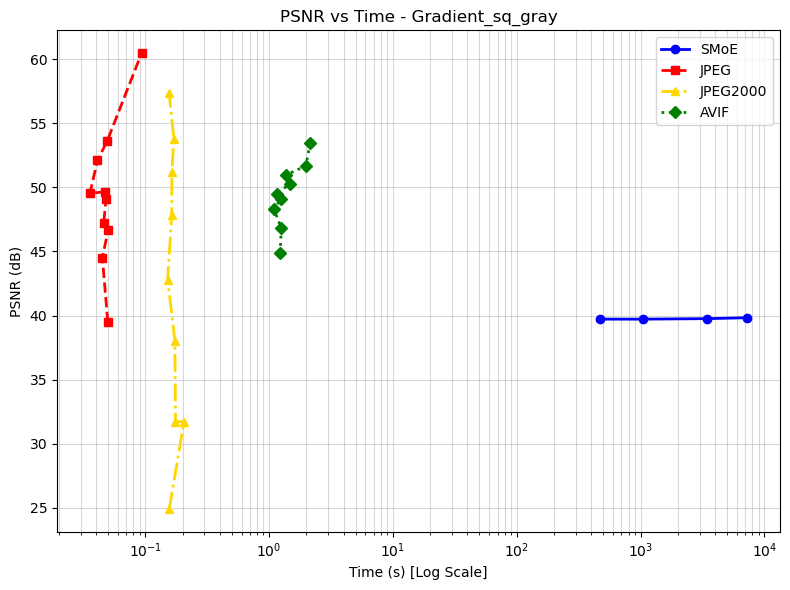

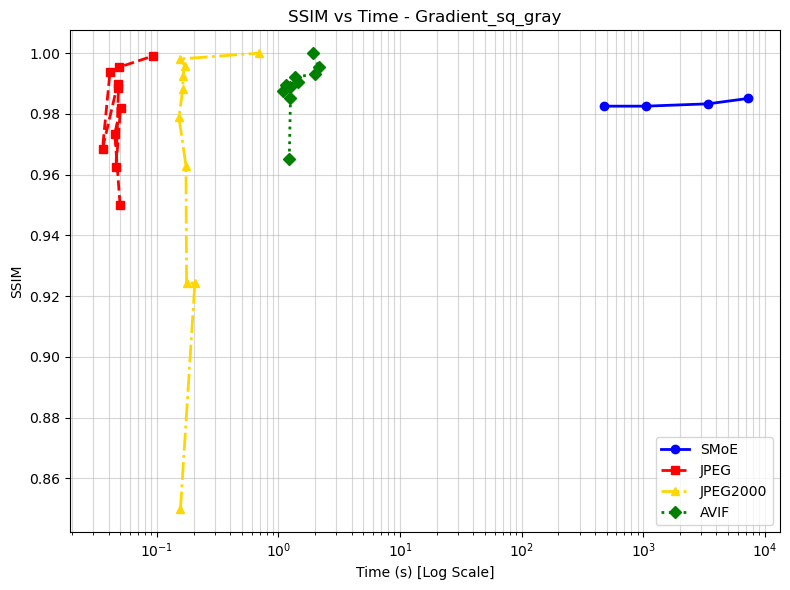

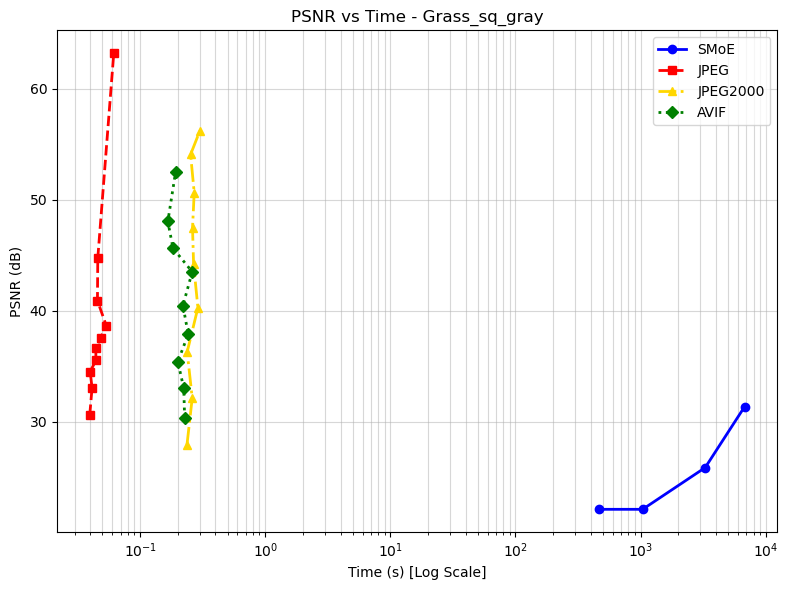

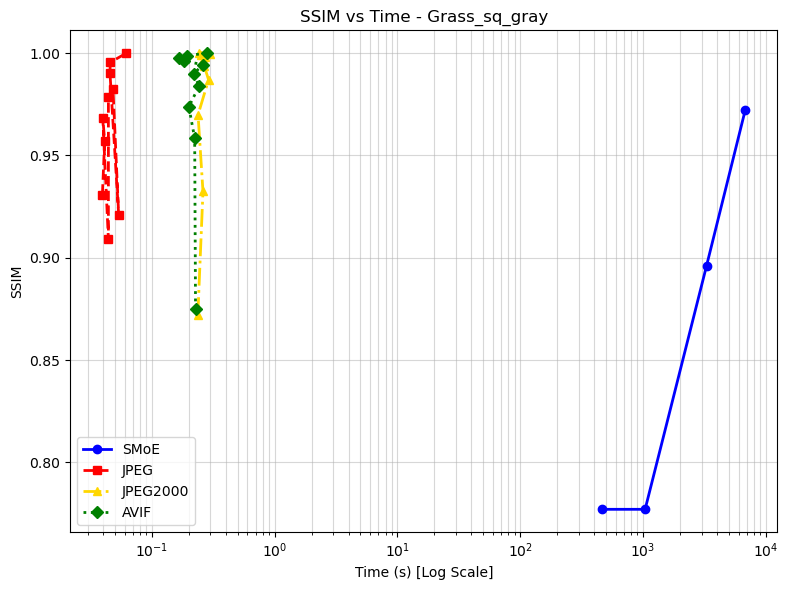

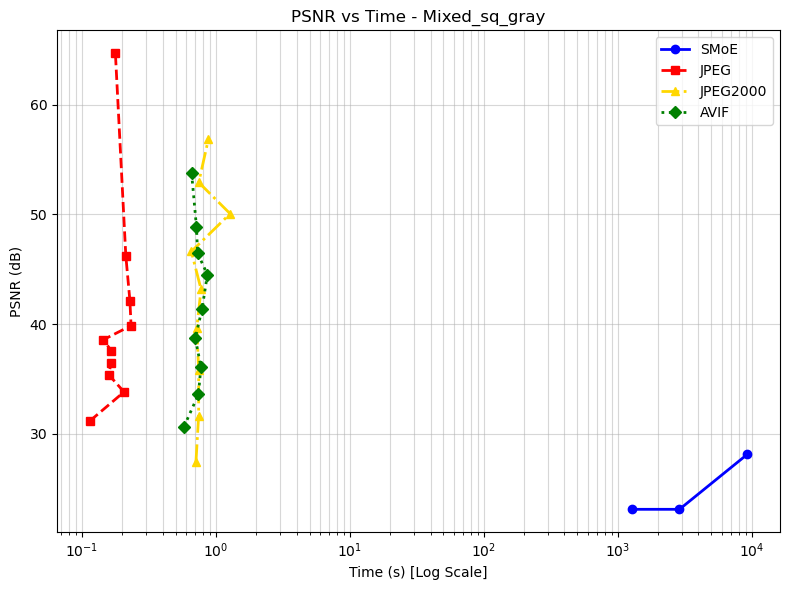

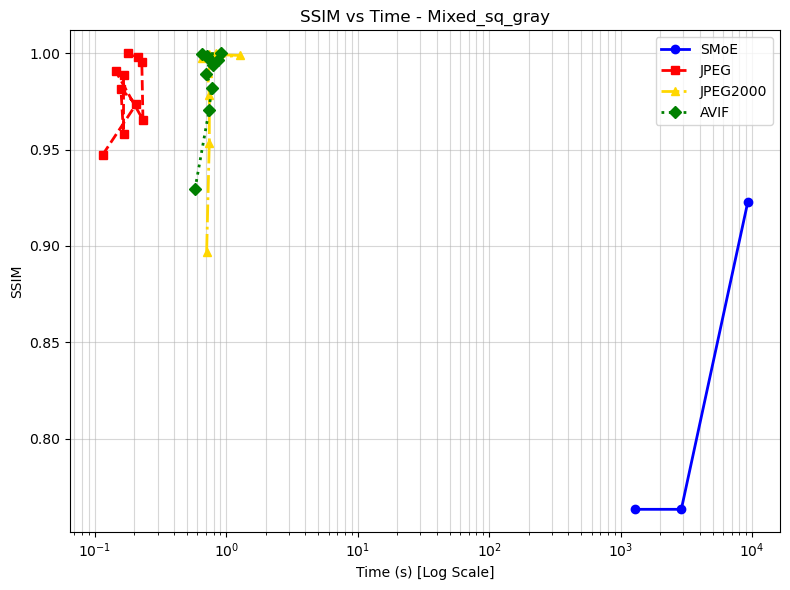

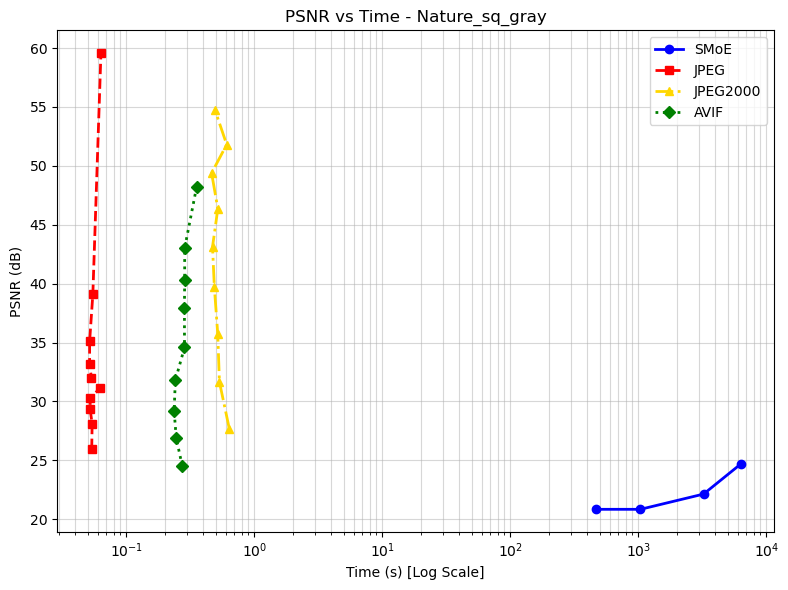

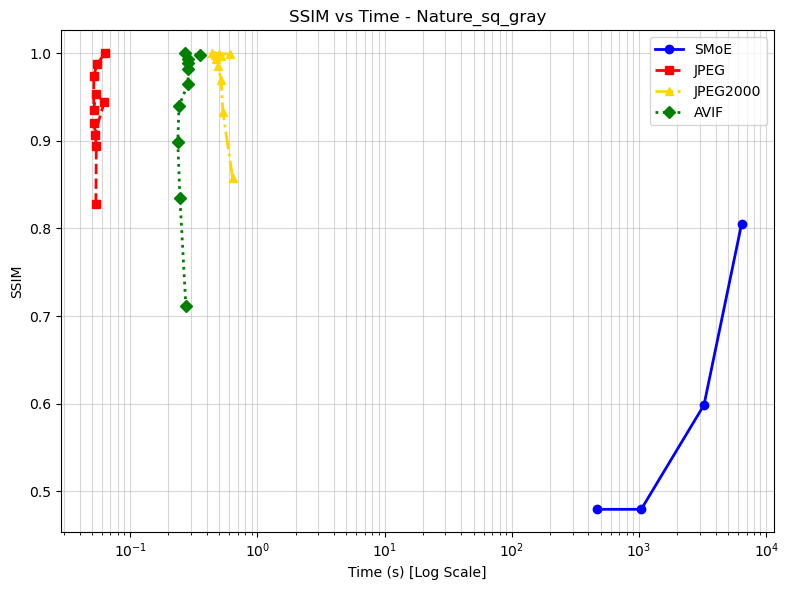

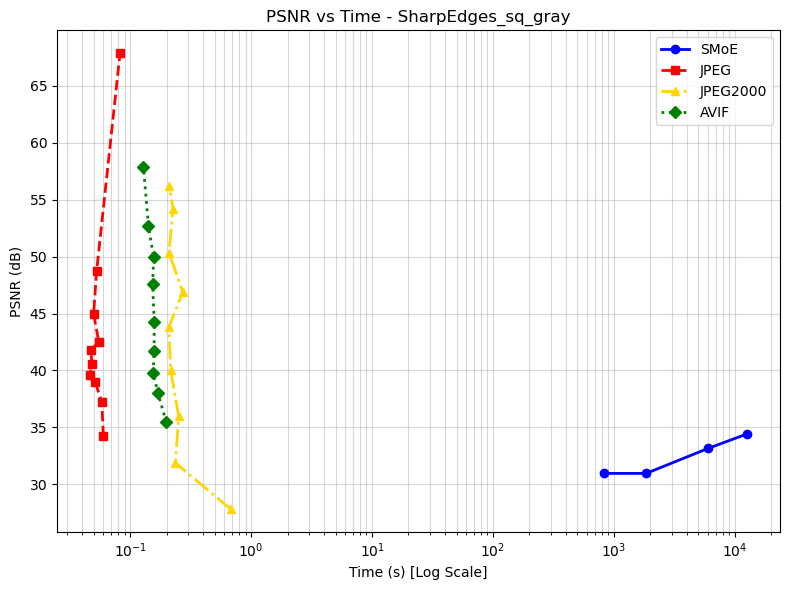

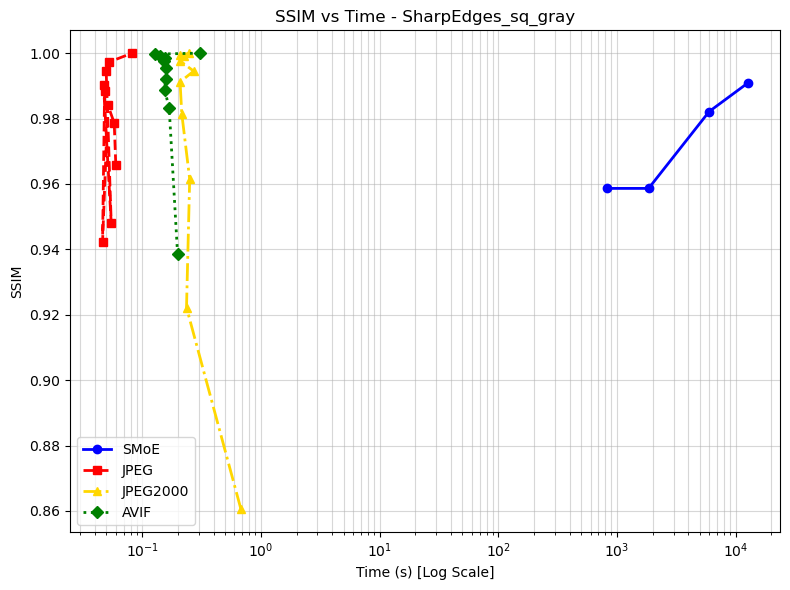

In [9]:
# --- Time vs Quality Analysis ---

# 1. Parse Time Data
time_files = {
    '16k': workspace_root / 'SMoE' / 'computationaltime' / '16ktime.txt',
    '32k': workspace_root / 'SMoE' / 'computationaltime' / '32ktime.txt',
    '64k': workspace_root / 'SMoE' / 'computationaltime' / '64ktime.txt',
    '96k': workspace_root / 'SMoE' / 'computationaltime' / '96ktime.txt',
}

# Inline fallback tables for when log files are missing/empty
fallback_tables = {
    '16k': """| Image          | Tiles | Total Time (s) | Time (min)    |
| -------------- | ----- | -------------- | ------------- |
| **Gradient**   | 9     | **473.7 s**    | **7.89 min**  |
| **Grass**      | 9     | **463.2 s**    | **7.72 min**  |
| **Nature**     | 9     | **463.8 s**    | **7.73 min**  |
| **SharpEdges** | 16    | **823.4 s**    | **13.72 min** |
| **Mixed**      | 25    | **1286.8 s**   | **21.45 min** |"""
}

# Map "Text File Name" to "File Name"
name_map = {
    'Gradient': 'Gradient_sq_gray',
    'Grass': 'Grass_sq_gray',
    'Nature': 'Nature_sq_gray',
    'SharpEdges': 'SharpEdges_sq_gray',
    'Mixed': 'Mixed_sq_gray'
}

# Structure: times[image_name][config_key] = time_in_seconds
times = {name: {} for name in name_map.values()}

print("Parsing time files...")
for config, path in time_files.items():
    if path.exists() and path.stat().st_size > 0:
        lines = path.read_text().splitlines()
    elif config in fallback_tables:
        print(f"Using inline data for {config}")
        lines = fallback_tables[config].splitlines()
    else:
        print(f"Skipping {config} (file missing or empty)")
        continue

    for line in lines:
        # Parse Markdown table row: | **Name** | Tiles | Time (s) | ...
        if '|' not in line or '---' in line or 'Total Time' in line:
            continue

        parts = [p.strip() for p in line.split('|')]
        if len(parts) < 4:
            continue

        # Name is in parts[1], Time is in parts[3]
        # Remove bold markers ** and whitespace
        raw_name = parts[1].replace('*', '').strip()
        # Time might be "1052.6 s" or just "1052.6"
        raw_time = parts[3].replace('*', '').replace('s', '').strip()

        if raw_name in name_map:
            img_key = name_map[raw_name]
            try:
                time_val = float(raw_time)
                times[img_key][config] = time_val
            except ValueError:
                print(f"Could not parse time for {raw_name} in {config}: {raw_time}")

# 2. Hard-coded JPEG timing/quality metrics (provided externally)
jpeg_time_metrics = {
    'Gradient_sq_gray': [
        {'quality': 10, 'time': 0.0498, 'psnr': 39.50, 'ssim': 0.9499},
        {'quality': 20, 'time': 0.0450, 'psnr': 44.53, 'ssim': 0.9735},
        {'quality': 30, 'time': 0.0502, 'psnr': 46.67, 'ssim': 0.9819},
        {'quality': 40, 'time': 0.0461, 'psnr': 47.21, 'ssim': 0.9626},
        {'quality': 50, 'time': 0.0483, 'psnr': 49.12, 'ssim': 0.9886},
        {'quality': 60, 'time': 0.0474, 'psnr': 49.67, 'ssim': 0.9897},
        {'quality': 70, 'time': 0.0357, 'psnr': 49.53, 'ssim': 0.9686},
        {'quality': 80, 'time': 0.0411, 'psnr': 52.11, 'ssim': 0.9937},
        {'quality': 90, 'time': 0.0491, 'psnr': 53.59, 'ssim': 0.9954},
        {'quality': 100, 'time': 0.0934, 'psnr': 60.48, 'ssim': 0.9991},
    ],
    'Grass_sq_gray': [
        {'quality': 10, 'time': 0.0396, 'psnr': 30.62, 'ssim': 0.9309},
        {'quality': 20, 'time': 0.0413, 'psnr': 33.03, 'ssim': 0.9570},
        {'quality': 30, 'time': 0.0399, 'psnr': 34.51, 'ssim': 0.9682},
        {'quality': 40, 'time': 0.0443, 'psnr': 35.51, 'ssim': 0.9091},
        {'quality': 50, 'time': 0.0443, 'psnr': 36.59, 'ssim': 0.9788},
        {'quality': 60, 'time': 0.0483, 'psnr': 37.56, 'ssim': 0.9823},
        {'quality': 70, 'time': 0.0537, 'psnr': 38.63, 'ssim': 0.9211},
        {'quality': 80, 'time': 0.0456, 'psnr': 40.91, 'ssim': 0.9905},
        {'quality': 90, 'time': 0.0459, 'psnr': 44.75, 'ssim': 0.9955},
        {'quality': 100, 'time': 0.0616, 'psnr': 63.21, 'ssim': 0.9999},
    ],
    'Nature_sq_gray': [
        {'quality': 10, 'time': 0.0538, 'psnr': 25.97, 'ssim': 0.8284},
        {'quality': 20, 'time': 0.0542, 'psnr': 28.11, 'ssim': 0.8939},
        {'quality': 30, 'time': 0.0522, 'psnr': 29.39, 'ssim': 0.9202},
        {'quality': 40, 'time': 0.0525, 'psnr': 30.32, 'ssim': 0.9063},
        {'quality': 50, 'time': 0.0627, 'psnr': 31.14, 'ssim': 0.9445},
        {'quality': 60, 'time': 0.0535, 'psnr': 31.99, 'ssim': 0.9530},
        {'quality': 70, 'time': 0.0518, 'psnr': 33.17, 'ssim': 0.9346},
        {'quality': 80, 'time': 0.0518, 'psnr': 35.10, 'ssim': 0.9739},
        {'quality': 90, 'time': 0.0549, 'psnr': 39.10, 'ssim': 0.9878},
        {'quality': 100, 'time': 0.0635, 'psnr': 59.57, 'ssim': 0.9998},
    ],
    'SharpEdges_sq_gray': [
        {'quality': 10, 'time': 0.0600, 'psnr': 34.24, 'ssim': 0.9659},
        {'quality': 20, 'time': 0.0582, 'psnr': 37.23, 'ssim': 0.9786},
        {'quality': 30, 'time': 0.0514, 'psnr': 38.96, 'ssim': 0.9842},
        {'quality': 40, 'time': 0.0464, 'psnr': 39.64, 'ssim': 0.9422},
        {'quality': 50, 'time': 0.0483, 'psnr': 40.59, 'ssim': 0.9884},
        {'quality': 60, 'time': 0.0473, 'psnr': 41.77, 'ssim': 0.9902},
        {'quality': 70, 'time': 0.0549, 'psnr': 42.53, 'ssim': 0.9481},
        {'quality': 80, 'time': 0.0498, 'psnr': 44.99, 'ssim': 0.9945},
        {'quality': 90, 'time': 0.0528, 'psnr': 48.77, 'ssim': 0.9973},
        {'quality': 100, 'time': 0.0824, 'psnr': 67.88, 'ssim': 1.0000},
    ],
    'Mixed_sq_gray': [
        {'quality': 10, 'time': 0.1145, 'psnr': 31.15, 'ssim': 0.9472},
        {'quality': 20, 'time': 0.2059, 'psnr': 33.80, 'ssim': 0.9734},
        {'quality': 30, 'time': 0.1580, 'psnr': 35.38, 'ssim': 0.9815},
        {'quality': 40, 'time': 0.1653, 'psnr': 36.48, 'ssim': 0.9581},
        {'quality': 50, 'time': 0.1655, 'psnr': 37.54, 'ssim': 0.9885},
        {'quality': 60, 'time': 0.1446, 'psnr': 38.57, 'ssim': 0.9905},
        {'quality': 70, 'time': 0.2324, 'psnr': 39.85, 'ssim': 0.9654},
        {'quality': 80, 'time': 0.2278, 'psnr': 42.13, 'ssim': 0.9954},
        {'quality': 90, 'time': 0.2123, 'psnr': 46.25, 'ssim': 0.9979},
        {'quality': 100, 'time': 0.1775, 'psnr': 64.73, 'ssim': 1.0000},
    ],
}

# 3. Hard-coded JPEG2000 timing/quality metrics captured from existing tables
jpeg2000_time_metrics = {
    'Gradient_sq_gray': [
        {'quality': 10, 'time': 0.1562, 'psnr': 24.88, 'ssim': 0.8498},
        {'quality': 20, 'time': 0.2053, 'psnr': 31.72, 'ssim': 0.9243},
        {'quality': 30, 'time': 0.1754, 'psnr': 31.72, 'ssim': 0.9243},
        {'quality': 40, 'time': 0.1734, 'psnr': 38.04, 'ssim': 0.9629},
        {'quality': 50, 'time': 0.1517, 'psnr': 42.77, 'ssim': 0.9789},
        {'quality': 60, 'time': 0.1634, 'psnr': 47.87, 'ssim': 0.9882},
        {'quality': 70, 'time': 0.1640, 'psnr': 51.23, 'ssim': 0.9926},
        {'quality': 80, 'time': 0.1701, 'psnr': 53.79, 'ssim': 0.9957},
        {'quality': 90, 'time': 0.1558, 'psnr': 57.34, 'ssim': 0.9981},
        {'quality': 100, 'time': 0.6900, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Grass_sq_gray': [
        {'quality': 10, 'time': 0.2370, 'psnr': 27.92, 'ssim': 0.8720},
        {'quality': 20, 'time': 0.2609, 'psnr': 32.12, 'ssim': 0.9324},
        {'quality': 30, 'time': 0.2379, 'psnr': 36.29, 'ssim': 0.9699},
        {'quality': 40, 'time': 0.2897, 'psnr': 40.26, 'ssim': 0.9870},
        {'quality': 50, 'time': 0.2676, 'psnr': 44.18, 'ssim': 0.9936},
        {'quality': 60, 'time': 0.2624, 'psnr': 47.48, 'ssim': 0.9965},
        {'quality': 70, 'time': 0.2707, 'psnr': 50.63, 'ssim': 0.9982},
        {'quality': 80, 'time': 0.2532, 'psnr': 54.08, 'ssim': 0.9992},
        {'quality': 90, 'time': 0.3001, 'psnr': 56.19, 'ssim': 0.9995},
        {'quality': 100, 'time': 0.2436, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Mixed_sq_gray': [
        {'quality': 10, 'time': 0.7091, 'psnr': 27.39, 'ssim': 0.8970},
        {'quality': 20, 'time': 0.7427, 'psnr': 31.64, 'ssim': 0.9536},
        {'quality': 30, 'time': 0.7431, 'psnr': 35.79, 'ssim': 0.9784},
        {'quality': 40, 'time': 0.7199, 'psnr': 39.66, 'ssim': 0.9896},
        {'quality': 50, 'time': 0.7738, 'psnr': 43.18, 'ssim': 0.9949},
        {'quality': 60, 'time': 0.6551, 'psnr': 46.62, 'ssim': 0.9975},
        {'quality': 70, 'time': 1.2760, 'psnr': 50.07, 'ssim': 0.9988},
        {'quality': 80, 'time': 0.7436, 'psnr': 52.93, 'ssim': 0.9994},
        {'quality': 90, 'time': 0.8798, 'psnr': 56.91, 'ssim': 0.9998},
        {'quality': 100, 'time': 0.8401, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Nature_sq_gray': [
        {'quality': 10, 'time': 0.6394, 'psnr': 27.67, 'ssim': 0.8571},
        {'quality': 20, 'time': 0.5352, 'psnr': 31.65, 'ssim': 0.9333},
        {'quality': 30, 'time': 0.5189, 'psnr': 35.76, 'ssim': 0.9693},
        {'quality': 40, 'time': 0.4885, 'psnr': 39.68, 'ssim': 0.9859},
        {'quality': 50, 'time': 0.4725, 'psnr': 43.13, 'ssim': 0.9932},
        {'quality': 60, 'time': 0.5199, 'psnr': 46.36, 'ssim': 0.9969},
        {'quality': 70, 'time': 0.4648, 'psnr': 49.39, 'ssim': 0.9984},
        {'quality': 80, 'time': 0.6097, 'psnr': 51.81, 'ssim': 0.9990},
        {'quality': 90, 'time': 0.4951, 'psnr': 54.71, 'ssim': 0.9995},
        {'quality': 100, 'time': 0.4379, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'SharpEdges_sq_gray': [
        {'quality': 10, 'time': 0.6804, 'psnr': 27.80, 'ssim': 0.8605},
        {'quality': 20, 'time': 0.2366, 'psnr': 31.88, 'ssim': 0.9222},
        {'quality': 30, 'time': 0.2516, 'psnr': 35.99, 'ssim': 0.9615},
        {'quality': 40, 'time': 0.2158, 'psnr': 40.05, 'ssim': 0.9815},
        {'quality': 50, 'time': 0.2088, 'psnr': 43.80, 'ssim': 0.9912},
        {'quality': 60, 'time': 0.2719, 'psnr': 46.89, 'ssim': 0.9945},
        {'quality': 70, 'time': 0.2093, 'psnr': 50.34, 'ssim': 0.9976},
        {'quality': 80, 'time': 0.2259, 'psnr': 54.22, 'ssim': 0.9991},
        {'quality': 90, 'time': 0.2104, 'psnr': 56.21, 'ssim': 0.9993},
        {'quality': 100, 'time': 0.2489, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
}

# 4. Hard-coded AVIF timing/quality metrics captured from existing tables
avif_time_metrics = {
    'Gradient_sq_gray': [
        {'quality': 10, 'time': 1.2271, 'psnr': 44.87, 'ssim': 0.9652},
        {'quality': 20, 'time': 1.2551, 'psnr': 46.82, 'ssim': 0.9852},
        {'quality': 30, 'time': 1.0935, 'psnr': 48.31, 'ssim': 0.9876},
        {'quality': 40, 'time': 1.2469, 'psnr': 49.10, 'ssim': 0.9890},
        {'quality': 50, 'time': 1.1518, 'psnr': 49.48, 'ssim': 0.9894},
        {'quality': 60, 'time': 1.4613, 'psnr': 50.27, 'ssim': 0.9906},
        {'quality': 70, 'time': 1.3705, 'psnr': 50.98, 'ssim': 0.9921},
        {'quality': 80, 'time': 1.9793, 'psnr': 51.68, 'ssim': 0.9931},
        {'quality': 90, 'time': 2.1497, 'psnr': 53.47, 'ssim': 0.9953},
        {'quality': 100, 'time': 1.9334, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Grass_sq_gray': [
        {'quality': 10, 'time': 0.2269, 'psnr': 30.35, 'ssim': 0.8751},
        {'quality': 20, 'time': 0.2233, 'psnr': 33.02, 'ssim': 0.9584},
        {'quality': 30, 'time': 0.2002, 'psnr': 35.40, 'ssim': 0.9738},
        {'quality': 40, 'time': 0.2424, 'psnr': 37.88, 'ssim': 0.9839},
        {'quality': 50, 'time': 0.2200, 'psnr': 40.46, 'ssim': 0.9900},
        {'quality': 60, 'time': 0.2610, 'psnr': 43.50, 'ssim': 0.9944},
        {'quality': 70, 'time': 0.1833, 'psnr': 45.62, 'ssim': 0.9961},
        {'quality': 80, 'time': 0.1666, 'psnr': 48.04, 'ssim': 0.9975},
        {'quality': 90, 'time': 0.1919, 'psnr': 52.46, 'ssim': 0.9988},
        {'quality': 100, 'time': 0.2835, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Mixed_sq_gray': [
        {'quality': 10, 'time': 0.5782, 'psnr': 30.64, 'ssim': 0.9295},
        {'quality': 20, 'time': 0.7393, 'psnr': 33.57, 'ssim': 0.9703},
        {'quality': 30, 'time': 0.7727, 'psnr': 36.08, 'ssim': 0.9821},
        {'quality': 40, 'time': 0.7012, 'psnr': 38.70, 'ssim': 0.9894},
        {'quality': 50, 'time': 0.7873, 'psnr': 41.37, 'ssim': 0.9937},
        {'quality': 60, 'time': 0.8635, 'psnr': 44.52, 'ssim': 0.9966},
        {'quality': 70, 'time': 0.7292, 'psnr': 46.46, 'ssim': 0.9976},
        {'quality': 80, 'time': 0.7158, 'psnr': 48.83, 'ssim': 0.9985},
        {'quality': 90, 'time': 0.6582, 'psnr': 53.75, 'ssim': 0.9995},
        {'quality': 100, 'time': 0.9141, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'Nature_sq_gray': [
        {'quality': 10, 'time': 0.2742, 'psnr': 24.52, 'ssim': 0.7110},
        {'quality': 20, 'time': 0.2461, 'psnr': 26.88, 'ssim': 0.8353},
        {'quality': 30, 'time': 0.2369, 'psnr': 29.19, 'ssim': 0.8984},
        {'quality': 40, 'time': 0.2421, 'psnr': 31.80, 'ssim': 0.9397},
        {'quality': 50, 'time': 0.2854, 'psnr': 34.58, 'ssim': 0.9653},
        {'quality': 60, 'time': 0.2850, 'psnr': 37.93, 'ssim': 0.9823},
        {'quality': 70, 'time': 0.2863, 'psnr': 40.27, 'ssim': 0.9890},
        {'quality': 80, 'time': 0.2863, 'psnr': 43.01, 'ssim': 0.9938},
        {'quality': 90, 'time': 0.3551, 'psnr': 48.23, 'ssim': 0.9980},
        {'quality': 100, 'time': 0.2698, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
    'SharpEdges_sq_gray': [
        {'quality': 10, 'time': 0.1990, 'psnr': 35.44, 'ssim': 0.9385},
        {'quality': 20, 'time': 0.1691, 'psnr': 38.05, 'ssim': 0.9831},
        {'quality': 30, 'time': 0.1550, 'psnr': 39.79, 'ssim': 0.9888},
        {'quality': 40, 'time': 0.1576, 'psnr': 41.71, 'ssim': 0.9922},
        {'quality': 50, 'time': 0.1580, 'psnr': 44.25, 'ssim': 0.9954},
        {'quality': 60, 'time': 0.1532, 'psnr': 47.58, 'ssim': 0.9976},
        {'quality': 70, 'time': 0.1562, 'psnr': 49.93, 'ssim': 0.9985},
        {'quality': 80, 'time': 0.1415, 'psnr': 52.70, 'ssim': 0.9992},
        {'quality': 90, 'time': 0.1287, 'psnr': 57.85, 'ssim': 0.9997},
        {'quality': 100, 'time': 0.3095, 'psnr': float('inf'), 'ssim': 1.0000},
    ],
}

# 5. Get SMoE quality metrics for each configuration
def get_smoe_metrics_by_config(img_name):
    smoe_base = workspace_root / 'SMoE'
    # Map config key (e.g., '32k') to folder name
    config_folders = {
        '16k': '16k_100i_3535s',
        '32k': '32k_100i_7899s',
        '64k': '64k_100i_25201s',
        '96k': '96k_100i_43212s'
    }

    # Load original
    orig_path = images_path / f'{img_name}.png'
    if not orig_path.exists():
        orig_path = smoe_base / '16k_100i_3535s' / 'tf-smoe-master' / 'data' / f'{img_name}.png'

    if not orig_path.exists():
        return {}

    pil = Image.open(orig_path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)
    if orig.ndim == 3:
        orig_gray = (0.299 * orig[..., 0] + 0.587 * orig[..., 1] + 0.114 * orig[..., 2]).astype(np.uint8)
    else:
        orig_gray = orig

    results = {}

    for key, folder in config_folders.items():
        recon_path = smoe_base / folder / 'tf-smoe-master' / 'results' / f"{img_name}_reconstructed.png"
        if recon_path.exists():
            try:
                recon = np.array(Image.open(recon_path), dtype=np.uint8)
                if recon.ndim == 3:
                    recon_gray = (0.299 * recon[..., 0] + 0.587 * recon[..., 1] + 0.114 * recon[..., 2]).astype(np.uint8)
                else:
                    recon_gray = recon

                min_h = min(orig_gray.shape[0], recon_gray.shape[0])
                min_w = min(orig_gray.shape[1], recon_gray.shape[1])

                p = psnr(orig_gray[:min_h, :min_w], recon_gray[:min_h, :min_w])
                s = ssim(orig_gray[:min_h, :min_w], recon_gray[:min_h, :min_w])
                results[key] = {'psnr': p, 'ssim': s}
            except Exception:
                pass
    return results

# 6. Plotting
print("\n" + "="*60)
print("Generating Time vs Quality Graphs")
print("="*60)

for img_name in image_names:
    metrics = get_smoe_metrics_by_config(img_name)
    img_times = times.get(img_name, {})

    # Determine image path for JPEG metrics
    img_path = images_path / f'{img_name}.png'
    if not img_path.exists():
        img_path = workspace_root / 'SMoE' / '16k_100i_3535s' / 'tf-smoe-master' / 'data' / f'{img_name}.png'
        if not img_path.exists():
            print(f"Skipping {img_name} (file not found for JPEG timing)")
            continue

    # Collect SMoE points (time, metric, config)
    smoe_psnr_points = []
    smoe_ssim_points = []

    for config in ['16k', '32k', '64k', '96k']:
        if config in metrics and config in img_times:
            t = img_times[config]
            p = metrics[config]['psnr']
            s = metrics[config]['ssim']
            smoe_psnr_points.append((t, p, config))
            smoe_ssim_points.append((t, s, config))

    if not smoe_psnr_points:
        print(f"No complete SMoE data points for {img_name}")
        continue

    smoe_psnr_points.sort(key=lambda x: x[0])
    smoe_ssim_points.sort(key=lambda x: x[0])

    smoe_t_p = [pt[0] for pt in smoe_psnr_points]
    smoe_p_val = [pt[1] for pt in smoe_psnr_points]

    smoe_t_s = [pt[0] for pt in smoe_ssim_points]
    smoe_s_val = [pt[1] for pt in smoe_ssim_points]

    # Collect JPEG points (time, metric, quality) sorted by quality to keep adjacency
    jpeg_entries = jpeg_time_metrics.get(img_name, [])
    jpeg_psnr_points = sorted(
        [(entry['time'], entry['psnr'], entry['quality']) for entry in jpeg_entries],
        key=lambda x: x[2]
    )
    jpeg_ssim_points = sorted(
        [(entry['time'], entry['ssim'], entry['quality']) for entry in jpeg_entries],
        key=lambda x: x[2]
    )

    # Collect JPEG2000 points from stored metrics
    jpeg2000_entries = jpeg2000_time_metrics.get(img_name, [])
    jp2_psnr_points = sorted(
        [(entry['time'], entry['psnr'], entry['quality']) for entry in jpeg2000_entries],
        key=lambda x: x[2]
    )
    jp2_ssim_points = sorted(
        [(entry['time'], entry['ssim'], entry['quality']) for entry in jpeg2000_entries],
        key=lambda x: x[2]
    )

    # Collect AVIF points from stored metrics
    avif_entries = avif_time_metrics.get(img_name, [])
    avif_psnr_points = sorted(
        [(entry['time'], entry['psnr'], entry['quality']) for entry in avif_entries],
        key=lambda x: x[2]
    )
    avif_ssim_points = sorted(
        [(entry['time'], entry['ssim'], entry['quality']) for entry in avif_entries],
        key=lambda x: x[2]
    )

    # --- PSNR Plot ---
    plt.figure(figsize=(8, 6))
    smoe_style = algo_styles['SMoE']
    jpeg_style = algo_styles['JPEG']
    jp2_style = algo_styles['JPEG2000']
    avif_style = algo_styles['AVIF']

    plt.plot(smoe_t_p, smoe_p_val, marker=smoe_style['marker'], linestyle='-', color=smoe_style['color'], linewidth=2, label='SMoE')

    if jpeg_psnr_points:
        jpeg_t_p = [pt[0] for pt in jpeg_psnr_points]
        jpeg_p_val = [pt[1] for pt in jpeg_psnr_points]
        plt.plot(jpeg_t_p, jpeg_p_val, marker=jpeg_style['marker'], linestyle='--', color=jpeg_style['color'], linewidth=2, label='JPEG')

    if jp2_psnr_points:
        jp2_t_p = [pt[0] for pt in jp2_psnr_points]
        jp2_p_val = [pt[1] for pt in jp2_psnr_points]
        plt.plot(jp2_t_p, jp2_p_val, marker=jp2_style['marker'], linestyle='-.', color=jp2_style['color'], linewidth=2, label='JPEG2000')

    if avif_psnr_points:
        avif_t_p = [pt[0] for pt in avif_psnr_points]
        avif_p_val = [pt[1] for pt in avif_psnr_points]
        plt.plot(avif_t_p, avif_p_val, marker=avif_style['marker'], linestyle=':', color=avif_style['color'], linewidth=2, label='AVIF')

    plt.xscale('log')
    plt.xlabel('Time (s) [Log Scale]')
    plt.ylabel('PSNR (dB)')
    plt.title(f'PSNR vs Time - {img_name}')
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- SSIM Plot ---
    plt.figure(figsize=(8, 6))
    plt.plot(smoe_t_s, smoe_s_val, marker=smoe_style['marker'], linestyle='-', color=smoe_style['color'], linewidth=2, label='SMoE')

    if jpeg_ssim_points:
        jpeg_t_s = [pt[0] for pt in jpeg_ssim_points]
        jpeg_s_val = [pt[1] for pt in jpeg_ssim_points]
        plt.plot(jpeg_t_s, jpeg_s_val, marker=jpeg_style['marker'], linestyle='--', color=jpeg_style['color'], linewidth=2, label='JPEG')

    if jp2_ssim_points:
        jp2_t_s = [pt[0] for pt in jp2_ssim_points]
        jp2_s_val = [pt[1] for pt in jp2_ssim_points]
        plt.plot(jp2_t_s, jp2_s_val, marker=jp2_style['marker'], linestyle='-.', color=jp2_style['color'], linewidth=2, label='JPEG2000')

    if avif_ssim_points:
        avif_t_s = [pt[0] for pt in avif_ssim_points]
        avif_s_val = [pt[1] for pt in avif_ssim_points]
        plt.plot(avif_t_s, avif_s_val, marker=avif_style['marker'], linestyle=':', color=avif_style['color'], linewidth=2, label='AVIF')

    plt.xscale('log')
    plt.xlabel('Time (s) [Log Scale]')
    plt.ylabel('SSIM')
    plt.title(f'SSIM vs Time - {img_name}')
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()



Computing Spatial Information (SI) vs Quality curves...

Processing SI for Gradient_sq_gray...


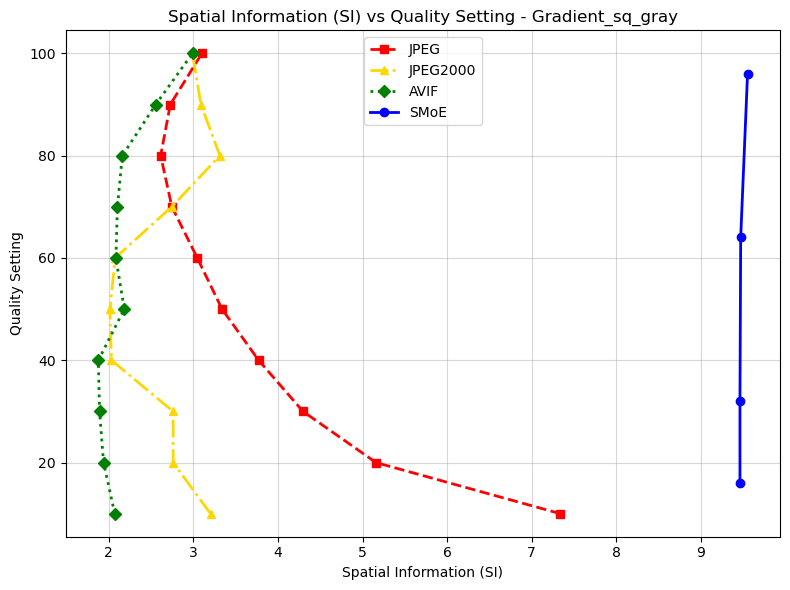


Processing SI for Grass_sq_gray...


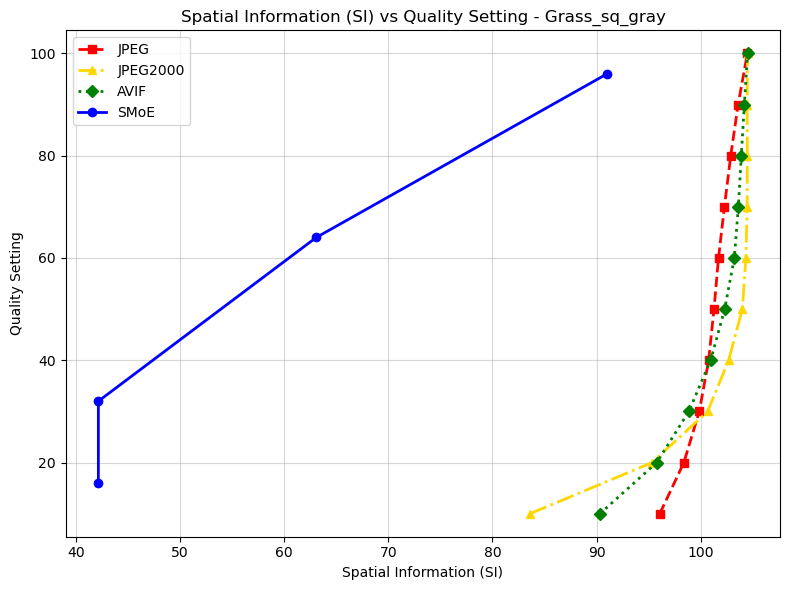


Processing SI for Mixed_sq_gray...


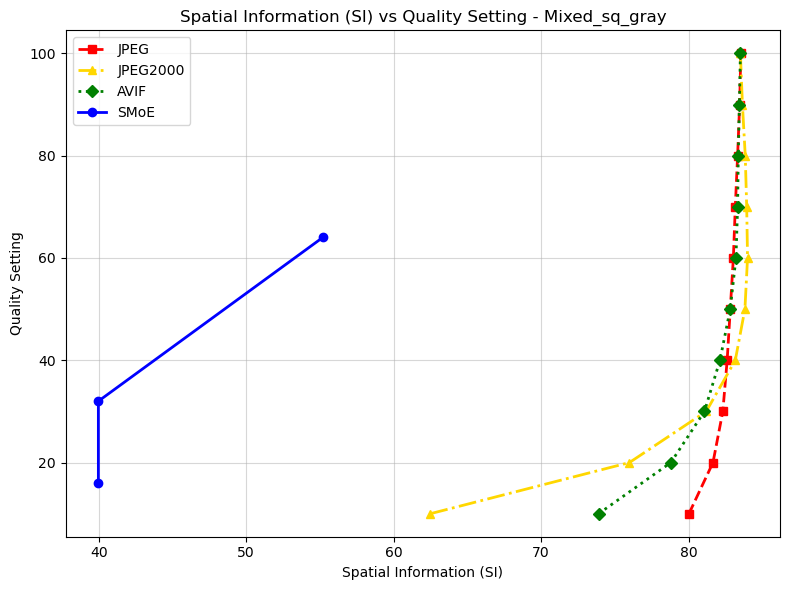


Processing SI for Nature_sq_gray...


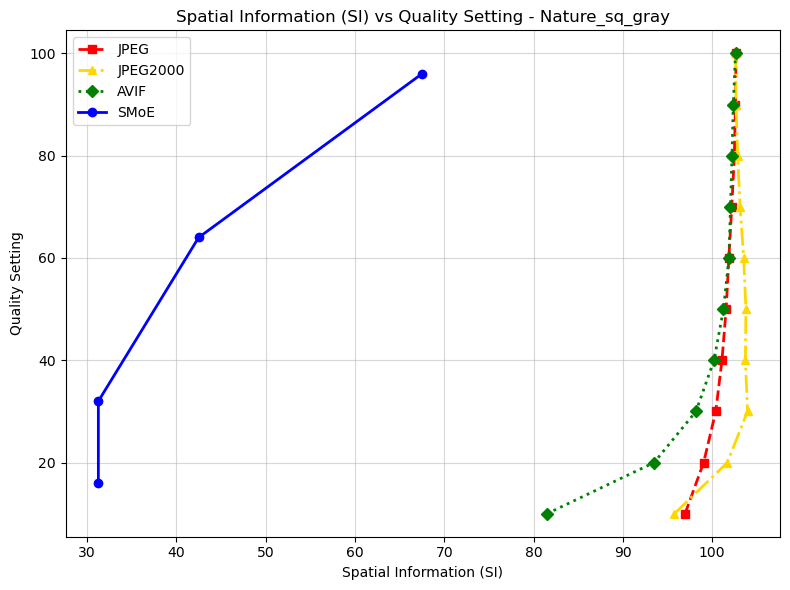


Processing SI for SharpEdges_sq_gray...


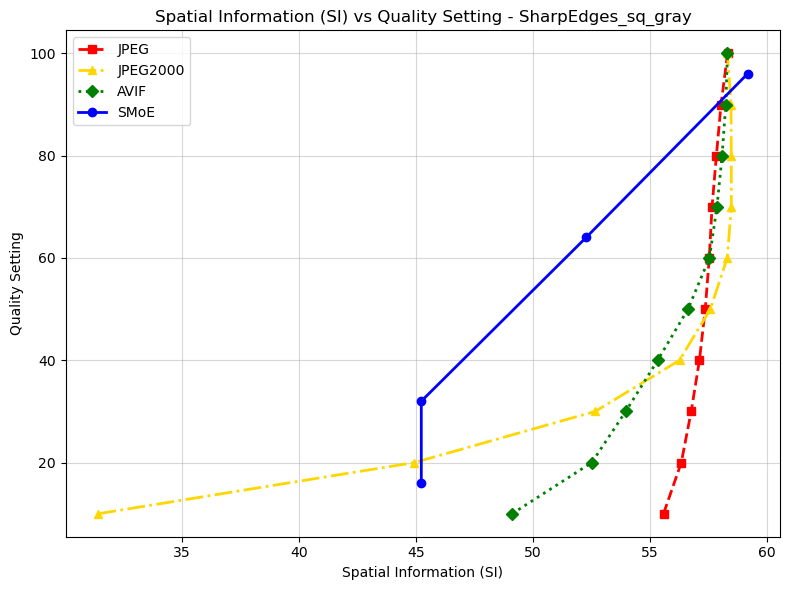

In [10]:
# --- Quality vs Spatial Information (SI) Analysis ---
jpeg_quality_levels = list(range(10, 101, 10))
jp2_quality_levels = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
jp2_psnr_targets = [28, 32, 36, 40, 44, 48, 52, 56, 60, 70]
avif_quality_levels = list(range(10, 101, 10))
smoe_configs_for_si = [('16k', 16), ('32k', 32), ('64k', 64), ('96k', 96)]  # (config, plotted quality surrogate)
smoe_config_suffix = {'16k': '3535s', '32k': '7899s', '64k': '25201s', '96k': '43212s'}
jpeg_subsampling = 0

def compute_si(img_array):
    """Compute Spatial Information (SI) as defined in ITU-T Rec. P.910."""
    if img_array.ndim == 3:
        gray = (0.299 * img_array[..., 0] + 0.587 * img_array[..., 1] + 0.114 * img_array[..., 2]).astype(np.float64)
    else:
        gray = img_array.astype(np.float64)

    padded = np.pad(gray, ((1, 1), (1, 1)), mode='reflect')
    gx = (
        -1 * padded[:-2, :-2] + 1 * padded[:-2, 2:]
        - 2 * padded[1:-1, :-2] + 2 * padded[1:-1, 2:]
        -1 * padded[2:, :-2] + 1 * padded[2:, 2:]
    )
    gy = (
        -1 * padded[:-2, :-2] - 2 * padded[:-2, 1:-1] - 1 * padded[:-2, 2:]
        + 1 * padded[2:, :-2] + 2 * padded[2:, 1:-1] + 1 * padded[2:, 2:]
    )
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    return float(np.std(magnitude))

codec_si_data = {codec: {} for codec in ['JPEG', 'JPEG2000', 'AVIF', 'SMoE']}
print("\n" + "=" * 60)
print("Computing Spatial Information (SI) vs Quality curves...")
print("=" * 60)

for img_name in image_names:
    print(f"\nProcessing SI for {img_name}...")
    img_path = images_path / f'{img_name}.png'
    if not img_path.exists():
        img_path = workspace_root / 'SMoE' / '16k_100i_3535s' / 'tf-smoe-master' / 'data' / f'{img_name}.png'
        if not img_path.exists():
            print(f"Skipping {img_name} (source image missing)")
            continue

    pil_img = Image.open(img_path).convert('RGB')

    # JPEG
    codec_si_data['JPEG'][img_name] = []
    for q in jpeg_quality_levels:
        buf = io.BytesIO()
        try:
            pil_img.save(buf, format='JPEG', quality=q, subsampling=jpeg_subsampling, optimize=True)
        except Exception as exc:
            print(f"  JPEG encode failed at Q={q}: {exc}")
            continue
        buf.seek(0)
        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        si_val = compute_si(rec)
        codec_si_data['JPEG'][img_name].append((q, si_val))

    # JPEG2000
    codec_si_data['JPEG2000'][img_name] = []
    for quality, psnr_target in zip(jp2_quality_levels, jp2_psnr_targets):
        buf = io.BytesIO()
        try:
            if quality == 100:
                pil_img.save(buf, 'JPEG2000', irreversible=False)
            else:
                pil_img.save(buf, 'JPEG2000', quality_mode='dB', quality_layers=[psnr_target])
        except Exception as exc:
            print(f"  JPEG2000 encode failed at Q={quality}: {exc}")
            continue
        buf.seek(0)
        try:
            rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        except Exception as exc:
            print(f"  JPEG2000 decode failed at Q={quality}: {exc}")
            continue
        si_val = compute_si(rec)
        codec_si_data['JPEG2000'][img_name].append((quality, si_val))

    # AVIF
    codec_si_data['AVIF'][img_name] = []
    for q in avif_quality_levels:
        buf = io.BytesIO()
        try:
            pil_img.save(buf, format='AVIF', quality=int(q))
        except Exception as exc:
            print(f"  AVIF encode failed at Q={q}: {exc}")
            continue
        buf.seek(0)
        try:
            rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        except Exception as exc:
            print(f"  AVIF decode failed at Q={q}: {exc}")
            continue
        si_val = compute_si(rec)
        codec_si_data['AVIF'][img_name].append((q, si_val))

    # SMoE
    codec_si_data['SMoE'][img_name] = []
    for config_key, quality_surrogate in smoe_configs_for_si:
        suffix = smoe_config_suffix.get(config_key)
        if suffix is None:
            continue
        recon_path = workspace_root / 'SMoE' / f'{config_key}_100i_{suffix}' / 'tf-smoe-master' / 'results' / f"{img_name}_reconstructed.png"
        if not recon_path.exists():
            continue
        try:
            recon = np.array(Image.open(recon_path), dtype=np.uint8)
        except Exception as exc:
            print(f"  SMoE load failed for {config_key}: {exc}")
            continue
        si_val = compute_si(recon)
        codec_si_data['SMoE'][img_name].append((quality_surrogate, si_val))

    # Plot per image
    plt.figure(figsize=(8, 6))
    jpeg_style = algo_styles['JPEG']
    jp2_style = algo_styles['JPEG2000']
    avif_style = algo_styles['AVIF']
    smoe_style = algo_styles['SMoE']

    if codec_si_data['JPEG'][img_name]:
        jpeg_points = sorted(codec_si_data['JPEG'][img_name], key=lambda x: x[0])
        plt.plot([p[1] for p in jpeg_points], [p[0] for p in jpeg_points], marker=jpeg_style['marker'], linestyle='--', color=jpeg_style['color'], linewidth=2, label='JPEG')

    if codec_si_data['JPEG2000'][img_name]:
        jp2_points = sorted(codec_si_data['JPEG2000'][img_name], key=lambda x: x[0])
        plt.plot([p[1] for p in jp2_points], [p[0] for p in jp2_points], marker=jp2_style['marker'], linestyle='-.', color=jp2_style['color'], linewidth=2, label='JPEG2000')

    if codec_si_data['AVIF'][img_name]:
        avif_points = sorted(codec_si_data['AVIF'][img_name], key=lambda x: x[0])
        plt.plot([p[1] for p in avif_points], [p[0] for p in avif_points], marker=avif_style['marker'], linestyle=':', color=avif_style['color'], linewidth=2, label='AVIF')

    if codec_si_data['SMoE'][img_name]:
        smoe_points = sorted(codec_si_data['SMoE'][img_name], key=lambda x: x[0])
        plt.plot([p[1] for p in smoe_points], [p[0] for p in smoe_points], marker=smoe_style['marker'], linestyle='-', color=smoe_style['color'], linewidth=2, label='SMoE')

    plt.xlabel('Spatial Information (SI)')
    plt.ylabel('Quality Setting')
    plt.title(f'Spatial Information (SI) vs Quality Setting - {img_name}')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()
